# Shearing and scaling 2-D NMR signals — step by step

Following Grandinetti *et al.*, *Prog. NMR Spectrosc.* **59** (2011) 121–196, Section 5 (pp. 172–177, Eqs. 186–216, Figs. 64–68).

**Plan (one step per section, each with its own numerical checks before moving on):**

1. **Shear parallel to $t_2$** (Eqs. 188, 193, 196) — *this section*
2. Scale $t_1$ after the shear (Eqs. 197–203): the F1 axis and what frequency it reports
3. Shear parallel to $t_1$ and scale $t_2$ (Eqs. 189, 194, 204–211)
4. Double shear and scale (Eqs. 212–216, Fig. 68)
5. Real data: raw `ser` → (t₁, ω₂), States/echo–antiecho, shifted echo, carrier vs. reference, F1 ppm after scaling, sidebands at non-integer positions
6. Move into `opennmr.notebook`, tests, GUI

**Conventions used throughout**
* Array `s[n1, n2]`: axis 0 is $t_1$ (indirect), axis 1 is $t_2$ (direct), matching `two_d.py`.
* Precession is written as $e^{+i 2\pi \nu t}$ and transforms use **numpy's kernel** $e^{-i\omega t}$ (`np.fft.fft`). The sign of every phase ramp below follows from that choice, **not** from the paper's printed equations (see the sign note below).
* Frequencies come from `np.fft.fftfreq` in its native (unshifted) order, so the phase ramp and the FFT output can't fall out of step through a misplaced `fftshift`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.linewidth": 0.8})
TWO_PI = 2 * np.pi

## 1.1 A synthetic signal with a known echo line

We need data for which the right answer is known exactly. Each site has isotropic frequencies $\nu^{iso}_1, \nu^{iso}_2$ and an anisotropic (inhomogeneous) frequency $\delta$, distributed over many crystallites, that enters the two periods with weights $p_1, p_2$:

$$s(t_1,t_2)=\sum_{\text{sites}}\sum_k w_k\,e^{i2\pi[(\nu^{iso}_1+p_1\delta_k)t_1+(\nu^{iso}_2+p_2\delta_k)t_2]}\,e^{-t_1/T_2^{(1)}-t_2/T_2}.$$

The $\delta$-dependent phase vanishes for every crystallite on the line $p_1t_1+p_2t_2=0$. That is the paper's echo line $a^{[1]}t_1+a^{[2]}t_2=0$ (Eq. 195), with $a^{[1]}=p_1$, $a^{[2]}=p_2$, so the shear ratio (Eq. 196) is

$$\kappa^{(t_2)}=a^{[1]}/a^{[2]}=p_1/p_2 .$$

I use $p_1=-7/9,\ p_2=1$ (the $I=3/2$ 3QMAS ratio): the echo then sits at $t_2=\tfrac79 t_1$, and $\kappa^{(t_2)}=-7/9$. The sampling is chosen so that $|\kappa|\,\Delta t_1/\Delta t_2 = 1.944$ is **not** an integer, so the shear needs sub-dwell shifts.

In [2]:
def echo_signal(n1, n2, dw1, dw2, sites, p1, p2, sigma_hz=2000.0,
                T2=1.0e-3, T2_1=4.0e-3, n_cryst=401, t2_values=None, t1_0=0.0):
    # Complex 2-D time signal s[t1, t2] with an inhomogeneous echo along p1*t1 + p2*t2 = 0.
    #   sites     : list of (nu1_iso [Hz], nu2_iso [Hz], amplitude)
    #   sigma_hz  : Gaussian width of the anisotropic frequency distribution (Hz); 0 -> one crystallite
    #   t2_values : optional (n1, n2) array of t2 times at which to evaluate (used for the analytic answer)
    t1 = t1_0 + np.arange(n1) * dw1
    if sigma_hz > 0:
        delta = np.linspace(-4, 4, n_cryst) * sigma_hz
        w = np.exp(-0.5 * (delta / sigma_hz) ** 2); w /= w.sum()
    else:
        delta, w = np.array([0.0]), np.array([1.0])
    if t2_values is None:
        t2_values = np.broadcast_to(np.arange(n2) * dw2, (n1, n2))
    s = np.zeros((n1, t2_values.shape[1]), complex)
    for nu1, nu2, amp in sites:
        f1 = nu1 + p1 * delta                      # (K,)
        f2 = nu2 + p2 * delta                      # (K,)
        A1 = w * np.exp(1j * TWO_PI * np.outer(t1, f1))            # (n1, K)
        # t2 phase depends on the row when t2_values is row-dependent
        ph2 = np.exp(1j * TWO_PI * t2_values[:, :, None] * f2)     # (n1, n2, K)
        s += amp * np.einsum("ik,ijk->ij", A1, ph2)
    s *= np.exp(-t1 / T2_1)[:, None] * np.exp(-np.clip(t2_values, 0, None) / T2)
    return s

# Acquisition parameters
n1, n2 = 64, 256
dw1, dw2 = 50e-6, 20e-6           # SW1 = 20 kHz, SW2 = 50 kHz
p1, p2 = -7/9, 1.0
kappa_t2 = p1 / p2                 # Eq. 196
sites = [(3000.0, -2000.0, 1.0), (-4000.0, 5000.0, 0.7)]

s = echo_signal(n1, n2, dw1, dw2, sites, p1, p2)
t1 = np.arange(n1) * dw1
t2 = np.arange(n2) * dw2
print(f"kappa(t2) = {kappa_t2:.4f};  |kappa|*dw1/dw2 = {abs(kappa_t2)*dw1/dw2:.4f} (non-integer)")

kappa(t2) = -0.7778;  |kappa|*dw1/dw2 = 1.9444 (non-integer)


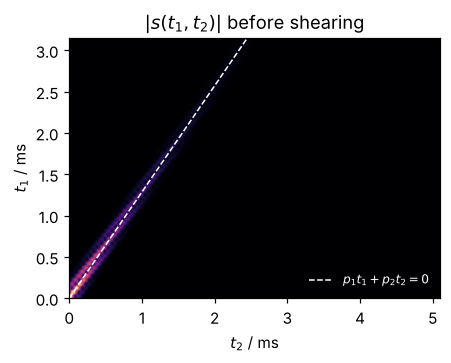

In [3]:
fig, ax = plt.subplots(figsize=(4.2, 3.4))
ax.imshow(np.abs(s), origin="lower", aspect="auto", cmap="magma",
          extent=[0, t2[-1]*1e3, 0, t1[-1]*1e3])
ax.plot(t2*1e3, -t2/kappa_t2*1e3, "--", c="w", lw=1, label=r"$p_1t_1+p_2t_2=0$")
ax.set(xlabel=r"$t_2$ / ms", ylabel=r"$t_1$ / ms", ylim=(0, t1[-1]*1e3),
       title=r"$|s(t_1,t_2)|$ before shearing")
ax.legend(loc="lower right", fontsize=8, frameon=False, labelcolor="w")
plt.tight_layout(); plt.show()

## 1.2 The shear parallel to $t_2$

The passive coordinate change (Eq. 188) is $t_1'=t_1,\ t_2'=t_2+\kappa^{(t_2)}t_1$, which puts the echo line at $t_2'=0$. The **active** version moves the signal instead:

$$s'(t_1,t_2)=s\big(t_1,\;t_2-\kappa^{(t_2)}t_1\big),$$

a $t_1$-dependent translation along $t_2$. Done by interpolation it would need a skew grid (Fig. 66B). Done with the shift theorem it's exact for any sub-dwell shift: Fourier transform along $t_2$, multiply each row by a linear phase, transform back (Eq. 193, Fig. 67).

With numpy's kernel, $s(t-\tau)\leftrightarrow e^{-i\omega\tau}S(\omega)$ and $\tau=\kappa^{(t_2)}t_1$, so

$$S'(t_1,\omega_2)=e^{-i\,\omega_2\,\kappa^{(t_2)}\,t_1}\,S(t_1,\omega_2)=e^{+i\,\omega_2\,\kappa^{(\omega_1)}\,t_1}\,S(t_1,\omega_2),\qquad \kappa^{(\omega_1)}=-\kappa^{(t_2)}\ \text{(Eq. 200)}.$$

**Sign note.** Eq. 193 prints $e^{+i\omega_2\kappa^{(t_2)}t_1}$ and Fig. 67 prints $e^{-i\omega_2\kappa^{(\omega_1)}t_1}$. Those two agree with each other, but both are the **opposite** sign to the result above, and to the paper's own shift theorem (Eq. 182, $s(t+\Delta t)\leftrightarrow e^{i\omega\Delta t}s(\omega)$). The likely cause is a different frequency sign convention ($\omega=-\gamma B$) in that part of the paper. Either way, the sign has to be fixed by numerical tests, not taken from print, and that's what 1.3 does.

**Three things that matter on discrete data**
1. **Wrap-around and the $t_2'$ axis.** The Fourier shift is circular (Fig. 66C), so each row is a *permutation* of its samples: nothing is lost and nothing overlaps. What changes is what each index means. For $\kappa<0$ the rising half of the echo moves to **negative** $t_2'$ and is stored at the end of the row, and where it starts depends on the row. With no zero-fill, no single index separates $t_2'\ge0$ from $t_2'<0$ for every row. Zero-filling $t_2$ by $\ge\lceil|\kappa|\,t_{1,\max}/\Delta t_2\rceil$ points gives a gap of zeros that does: index $<n_2$ is $t_2'=k\Delta t_2$, index $\ge n_2$ is $t_2'=(k-N_2)\Delta t_2$. For $\kappa>0$ everything moves later and all of $t_2'$ is positive. The function therefore returns its own $t_2'$ axis. Later steps (apodisation, half- vs whole-echo transforms, display) must use that axis and never assume "index $N/2$ and up is negative".
2. **Frequency origin.** $\omega_2$ must be the frequency **in the demodulated data**, i.e. relative to the carrier (the `fftfreq` grid). A ppm-referenced axis with a different zero adds a $t_1$-dependent phase $e^{-i\omega_{ref}\kappa t_1}$, which shifts everything in F1 by $\kappa\nu_{ref}$. That's a referencing question for Step 5, but the function shouldn't quietly allow it.
3. **The time origin of $t_1$** enters through $t_1$ itself, so a non-zero first $t_1$ increment has to be passed in.

In [4]:
def shear_t2_mixed(S_t1w2, w2, t1, kappa_t2):
    # Shear parallel to t2 applied in the mixed (t1, omega2) domain.
    # S_t1w2 : (n1, n2) complex, already FFT'd along t2 with np.fft.fft (no fftshift)
    # w2     : (n2,) angular frequency relative to the CARRIER, np.fft.fftfreq order [rad/s]
    # t1     : (n1,) t1 values [s] (include any non-zero first increment)
    # Returns S'(t1, omega2) corresponding to s'(t1, t2) = s(t1, t2 - kappa_t2 * t1).
    return S_t1w2 * np.exp(-1j * np.outer(t1, w2) * kappa_t2)


def shear_parallel_t2(s, dw1, dw2, kappa_t2, t1_0=0.0, pad=None):
    # Active shear parallel to t2 of a time-domain signal s[t1, t2] (t2 starts at 0).
    # pad : zeros appended along t2 first. None -> the minimum, ceil(|kappa| * t1_max / dw2),
    #       that keeps one row-independent boundary between t2' >= 0 and t2' < 0.
    # Returns (s_sheared, info). s_sheared is stored circularly (t2' = 0 at index 0, FFT-ready);
    # info["t2"] is the t2' value of every column, or None if pad is too small to define one.
    n1, n2 = s.shape
    t1 = t1_0 + np.arange(n1) * dw1
    shift_pts = kappa_t2 * t1 / dw2
    needed = int(np.ceil(np.max(np.abs(shift_pts)) - 1e-9))
    if pad is None:
        pad = needed
    sp = np.concatenate([s, np.zeros((n1, pad), s.dtype)], axis=1)
    N2 = sp.shape[1]
    w2 = TWO_PI * np.fft.fftfreq(N2, dw2)
    S = np.fft.fft(sp, axis=1)
    sp = np.fft.ifft(shear_t2_mixed(S, w2, t1, kappa_t2), axis=1)
    k = np.arange(N2)
    if pad < needed:
        t2p = None                                   # boundary differs row by row
    elif np.min(shift_pts) < 0:                      # some rows advanced -> negative t2'
        t2p = np.where(k < n2, k, k - N2) * dw2
    else:                                            # all rows delayed -> all t2' >= 0
        t2p = k * dw2
    return sp, {"n2_padded": N2, "pad": pad, "pad_needed": needed,
                "shift_pts": shift_pts, "t2": t2p}

## 1.3 Checks

Each check targets one way this can go wrong. All have to pass before Step 2.

**Check A — exact integer shift.** If $|\kappa|\Delta t_1$ is a whole number of $\Delta t_2$, the shear has to equal `np.roll` row by row to machine precision. This settles the **sign** with no interpolation involved.

In [5]:
# Choose dw1 = 9*dw2 so that kappa*t1 = -7*n1*dw2 exactly
nA1, nA2, dwA2 = 16, 256, 20e-6
dwA1 = 9 * dwA2
sA = echo_signal(nA1, nA2, dwA1, dwA2, sites, p1, p2)
shA, infoA = shear_parallel_t2(sA, dwA1, dwA2, kappa_t2)

padded = np.concatenate([sA, np.zeros((nA1, infoA["pad"]), complex)], axis=1)
rolled = np.array([np.roll(row, int(round(k))) for row, k in zip(padded, infoA["shift_pts"])])
errA = np.max(np.abs(shA - rolled)) / np.max(np.abs(sA))
print(f"shift per t1 increment = {infoA['shift_pts'][1]:+.6f} points")
print(f"max |shear - roll| / max|s| = {errA:.2e}")
assert np.allclose(infoA["shift_pts"], np.round(infoA["shift_pts"]), atol=1e-9)
assert errA < 1e-12, "sign or bookkeeping error in the shear"
print("Check A passed")

shift per t1 increment = -7.000000 points
max |shear - roll| / max|s| = 7.52e-16
Check A passed


**Check B — the echo lands on $t_2'=0$ for every $t_1$ (non-integer shift).** Compare the sheared signal with the model evaluated directly at $(t_1,\,t_2'-\kappa t_1)$, i.e. the exact answer. The comparison is limited to times inside the originally sampled window, $0\le t_2'-\kappa t_1<T_2^{\max}$; outside it the measured data simply don't exist. Points within a few dwells of a truncation edge carry sinc-interpolation ringing from the edge, so two numbers are reported: the error over the whole window, and the error away from the edges.

In [6]:
shB, infoB = shear_parallel_t2(s, dw1, dw2, kappa_t2)
t2p = infoB["t2"]                                        # t2' of each sheared column
t2_src = t2p[None, :] - kappa_t2 * t1[:, None]           # original t2 that maps onto each point
inside = (t2_src >= 0) & (t2_src < n2 * dw2)
exact = echo_signal(n1, t2p.size, dw1, dw2, sites, p1, p2, t2_values=t2_src)
exact[~inside] = 0

scale = np.max(np.abs(s))
err_all = np.max(np.abs(shB - exact)) / scale
print(f"max relative error, every point            : {err_all:.2e}")
for e in (3, 6, 12):
    interior = inside & (t2_src > e*dw2) & (t2_src < (n2 - e) * dw2)
    print(f"max relative error, > {e:2d} dwells from edges : "
          f"{np.max(np.abs(shB - exact)[interior]) / scale:.2e}")
interior = inside & (t2_src > 6*dw2) & (t2_src < (n2 - 6) * dw2)
err_int = np.max(np.abs(shB - exact)[interior]) / scale
assert err_int < 5e-3

# Echo-top position, one site (two sites at different frequencies beat in |s| and move the maximum)
one = [sites[0]]
s1 = echo_signal(n1, n2, dw1, dw2, one, p1, p2)
sh1, i1 = shear_parallel_t2(s1, dw1, dw2, kappa_t2)
top = i1["t2"][np.argmax(np.abs(sh1), axis=1)]
print(f"\necho top, all t1 rows: {top.min()*1e6:+.1f} to {top.max()*1e6:+.1f} us  (dw2 = {dw2*1e6:.0f} us)")
assert np.all(np.abs(top) <= dw2)

# Non-zero first t1 increment: the echo only lands on t2' = 0 if t1_0 is passed in
t1_0 = 130e-6
s0 = echo_signal(n1, n2, dw1, dw2, one, p1, p2, t1_0=t1_0)
for given, lbl in [(t1_0, "t1_0 passed in"), (0.0, "t1_0 ignored  ")]:
    sh0, i0 = shear_parallel_t2(s0, dw1, dw2, kappa_t2, t1_0=given)
    tp = i0["t2"][np.argmax(np.abs(sh0), axis=1)]
    print(f"{lbl}: echo top {tp.min()*1e6:+6.1f} to {tp.max()*1e6:+6.1f} us")
    if given:
        assert np.all(np.abs(tp) <= dw2)
print(f"(offset expected when ignored: -kappa*t1_0 = {-kappa_t2*t1_0*1e6:+.1f} us)")
print("Check B passed")

max relative error, every point            : 3.95e-01
max relative error, >  3 dwells from edges : 5.24e-03
max relative error, >  6 dwells from edges : 3.14e-03
max relative error, > 12 dwells from edges : 1.74e-03



echo top, all t1 rows: -20.0 to +0.0 us  (dw2 = 20 us)


t1_0 passed in: echo top   +0.0 to   +0.0 us
t1_0 ignored  : echo top +100.0 to +100.0 us
(offset expected when ignored: -kappa*t1_0 = +101.1 us)
Check B passed


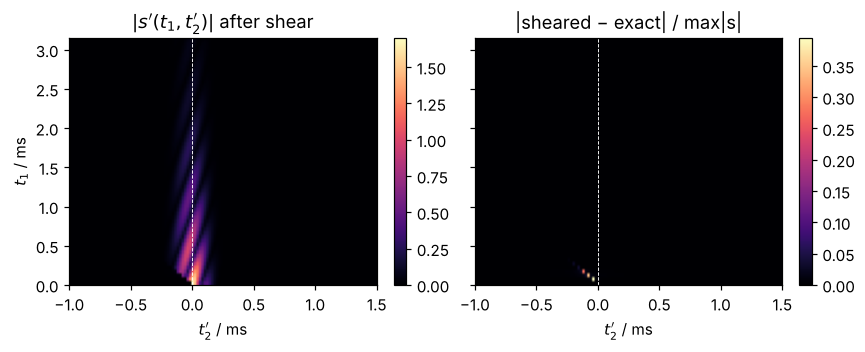

In [7]:
order = np.argsort(t2p)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.3), sharey=True)
for ax, data, ttl in [(axs[0], np.abs(shB[:, order]), r"$|s'(t_1,t_2')|$ after shear"),
                      (axs[1], np.abs((shB - exact)[:, order]) / scale, "|sheared − exact| / max|s|")]:
    im = ax.imshow(data, origin="lower", aspect="auto", cmap="magma",
                   extent=[t2p[order][0]*1e3, t2p[order][-1]*1e3, 0, t1[-1]*1e3])
    ax.axvline(0, c="w", lw=0.6, ls="--")
    ax.set(xlabel=r"$t_2'$ / ms", title=ttl, xlim=(-1.0, 1.5))
    plt.colorbar(im, ax=ax, fraction=0.046)
axs[0].set_ylabel(r"$t_1$ / ms")
plt.tight_layout(); plt.show()

The residual sits along the two edges of the sampled window (the start of acquisition, now on the line $t_2'=\kappa t_1$, and the truncated end of the FID). That's sinc interpolation of a signal that is cut off rather than decayed there. It falls with distance from the edge and doesn't come from the shear itself. Check A shows the shear is exact when no interpolation is needed. On real data the remedy is the usual one: let the FID decay, or apodise, before shearing.

**Check C — frequency.** One site, one crystallite (no distribution), so the signal is a single 2-D complex exponential at $(\nu_1,\nu_2)$. In the sheared coordinates its phase is $\nu_1t_1+\nu_2(t_2'-\kappa t_1)$, so it must become

$$\big(\nu_1-\kappa^{(t_2)}\nu_2,\ \nu_2\big)=\big(\nu_1+\kappa^{(\omega_1)}\nu_2,\ \nu_2\big)\quad(\text{F1 aliased into }\pm SW_1/2).$$

Two estimators failed first, and both failures are worth knowing about. (i) Picking the 2-D peak maximum missed by up to 40 Hz: the sheared window is a parallelogram, so the peak shape is skewed. (ii) Phase increments along a sheared *time-domain* row were off by a few Hz, because a single crystallite has full amplitude at $t_2=0$. That step, shifted by a fraction of a dwell, sinc-rings along the whole row.

The shear really happens in the mixed $(t_1,\omega_2)$ domain, so that's where to test it. For a separable signal every $\omega_2$ bin $k$ holds $e^{i2\pi\nu_1t_1}\times(\text{its own constant})$, leakage bins included. After the shear, bin $k$ must oscillate in $t_1$ at exactly $\nu_1-\kappa\,\nu_{2,k}$, where $\nu_{2,k}$ is the **bin frequency**. Its magnitude must not change at all. So the F2 position of the peak is untouched, and F1 picks up $-\kappa\nu_2$. (For the distributed signal the anisotropic part drops out of F1, since $p_1\delta-\kappa p_2\delta=0$; the spectra below show that.)

In [8]:
def phase_freq(x, dw):
    # Frequency (Hz) of a single complex exponential from its mean phase increment.
    return np.angle(np.sum(x[1:] * np.conj(x[:-1]))) / (TWO_PI * dw)

def alias(nu, sw):
    return (nu + sw / 2) % sw - sw / 2

def check_c(nu1, nu2, kap):
    sC = echo_signal(n1, n2, dw1, dw2, [(nu1, nu2, 1.0)], p1, p2, sigma_hz=0, T2=5e-3, T2_1=5e-3)
    shC, iC = shear_parallel_t2(sC, dw1, dw2, kap)
    N2 = iC["n2_padded"]
    before = np.fft.fft(np.pad(sC, ((0, 0), (0, iC["pad"]))), axis=1)   # (t1, omega2), unsheared
    after = np.fft.fft(shC, axis=1)                                     # (t1, omega2), sheared
    f2k = np.fft.fftfreq(N2, dw2)
    mag_err = np.max(np.abs(np.abs(after) - np.abs(before))) / np.max(np.abs(before))
    # F1 frequency of every omega2 bin holding > 1 % of the peak
    strong = np.flatnonzero(np.abs(after[0]) > 0.01 * np.abs(after[0]).max())
    got = np.array([phase_freq(after[:, k], dw1) for k in strong])
    expect = alias(nu1 - kap * f2k[strong], 1 / dw1)
    f1_err = np.max(np.abs(alias(got - expect, 1 / dw1)))
    kpk = strong[np.argmax(np.abs(after[0, strong]))]
    print(f"nu=({nu1:+6.0f},{nu2:+6.0f}) kappa={kap:+.3f}: peak bin nu2={f2k[kpk]:+8.1f} Hz -> F1 "
          f"{phase_freq(after[:, kpk], dw1):+9.3f} Hz; over {strong.size:3d} bins max F1 error "
          f"{f1_err:.1e} Hz; | |S'|-|S| | {mag_err:.1e}")
    return f1_err < 1e-6 and mag_err < 1e-12

results = [check_c(3000, -2000, kappa_t2),
           check_c(-4000, 5000, kappa_t2),
           check_c(1000, 15000, kappa_t2),     # -kappa*nu2 = 11.7 kHz: aliases in F1
           check_c(3000, -2000, +19/12)]       # opposite sign, |kappa| > 1
assert all(results)
print("Check C passed")

nu=( +3000, -2000) kappa=-0.778: peak bin nu2= -1978.9 Hz -> F1 +1460.862 Hz; over  80 bins max F1 error 3.6e-12 Hz; | |S'|-|S| | 7.2e-16
nu=( -4000, +5000) kappa=-0.778: peak bin nu2= +5013.2 Hz -> F1  -100.850 Hz; over  81 bins max F1 error 1.8e-12 Hz; | |S'|-|S| | 5.3e-16
nu=( +1000,+15000) kappa=-0.778: peak bin nu2=+15039.6 Hz -> F1 -7302.551 Hz; over  83 bins max F1 error 3.6e-12 Hz; | |S'|-|S| | 5.7e-16
nu=( +3000, -2000) kappa=+1.583: peak bin nu2= -1976.3 Hz -> F1 +6129.117 Hz; over 106 bins max F1 error 3.6e-12 Hz; | |S'|-|S| | 3.6e-16
Check C passed


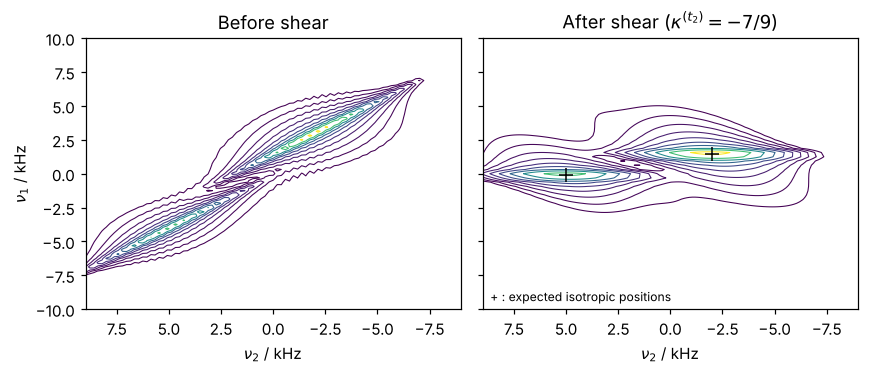

In [9]:
def spectrum(s_t, dw1, dw2):
    S = np.fft.fftshift(np.fft.fft2(s_t))
    f1 = np.fft.fftshift(np.fft.fftfreq(s_t.shape[0], dw1))
    f2 = np.fft.fftshift(np.fft.fftfreq(s_t.shape[1], dw2))
    return S, f1, f2

# Whole-echo transform needs t2 = 0 at index 0: shB is already circular in t2'
S0, f1, f2a = spectrum(s, dw1, dw2)
S1, _, f2b = spectrum(shB, dw1, dw2)

fig, axs = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
for ax, S, f2_, ttl in [(axs[0], S0, f2a, "Before shear"), (axs[1], S1, f2b, r"After shear ($\kappa^{(t_2)}=-7/9$)")]:
    A = np.abs(S); A /= A.max()
    ax.contour(f2_/1e3, f1/1e3, A, levels=np.geomspace(0.04, 0.9, 10), cmap="viridis", linewidths=0.7)
    ax.set(xlabel=r"$\nu_2$ / kHz", title=ttl, xlim=(9, -9))
for nu1, nu2, _ in sites:
    axs[1].plot(nu2/1e3, (nu1 - kappa_t2*nu2)/1e3, "+", c="k", ms=9)
axs[0].set(ylabel=r"$\nu_1$ / kHz", ylim=(-10, 10))
axs[1].text(0.02, 0.03, "+ : expected isotropic positions", transform=axs[1].transAxes, fontsize=8)
plt.tight_layout(); plt.show()

Before the shear, each site is a ridge with slope $\Delta\nu_1/\Delta\nu_2=p_1/p_2$. After it, each ridge lies parallel to $\nu_2$ at $\nu_1=\nu_1^{iso}-\kappa\nu_2^{iso}$, so the anisotropy has gone from F1. The $\nu_2$ widths look different only because the sheared signal is a whole echo (more $t_2'$ points, both halves).

**Check D — what zero-filling is for.** I first expected `pad=0` to corrupt the data. It doesn't. The circular shift only permutes each row, and for $\kappa<0$ the end of each row is exactly the part that has been emptied. What breaks is the **time axis**: with no gap, the boundary between $t_2'\ge0$ and $t_2'<0$ moves from row to row, so no single axis describes the array:

In [10]:
shD, infoD = shear_parallel_t2(s, dw1, dw2, kappa_t2, pad=0)
print("t2 axis returned with pad=0:", infoD["t2"])
print("pad needed for a single axis:", infoD["pad_needed"], "points")
# Per-row boundary index between positive-time and wrapped (negative-time) samples
bound = n2 + np.floor(infoD["shift_pts"]).astype(int)
print("first wrapped index, rows 0, 16, 32, 63:", bound[[0, 16, 32, 63]], " (of", n2, "points)")
# Integer-shift geometry (Check A): with pad=0 each row is exactly np.roll of the unpadded row
shA0, _ = shear_parallel_t2(sA, dwA1, dwA2, kappa_t2, pad=0)
rolled0 = np.array([np.roll(r, int(round(k))) for r, k in zip(sA, infoA["shift_pts"])])
print(f"pad=0, integer shifts: max |shear - roll| / max|s| = "
      f"{np.max(np.abs(shA0 - rolled0)) / np.max(np.abs(sA)):.1e}  -> a pure permutation, nothing lost")

t2 axis returned with pad=0: None
pad needed for a single axis: 123 points
first wrapped index, rows 0, 16, 32, 63: [256 224 193 133]  (of 256 points)
pad=0, integer shifts: max |shear - roll| / max|s| = 8.2e-16  -> a pure permutation, nothing lost


So the padding isn't about lost signal. It buys one shared $t_2'$ axis, which every later step (apodisation, half- vs whole-echo FT, plotting, Step 2's scaling) depends on. 

## Summary of Step 1

| | Result |
|---|---|
| Operation | $S'(t_1,\omega_2)=e^{-i\omega_2\kappa^{(t_2)}t_1}S(t_1,\omega_2)$, numpy kernel, $\omega_2$ relative to the carrier |
| Shear ratio | $\kappa^{(t_2)}=a^{[1]}/a^{[2]}$ (Eq. 196); $\kappa^{(\omega_1)}=-\kappa^{(t_2)}$ |
| Effect in frequency | peak $(\nu_1,\nu_2)\to(\nu_1-\kappa^{(t_2)}\nu_2,\ \nu_2)$ |
| Zero-fill | $\ge\lceil|\kappa|\,t_{1,\max}/\Delta t_2\rceil$ points along $t_2$, so that one $t_2'$ axis holds for every row (no signal is lost without it) |
| Paper's printed sign (Eq. 193 / Fig. 67) | opposite to numpy's convention; checks A and C fix it |

**Questions to settle before Step 2**
1. Shear ratio input: the paper gives $\kappa^{(t_2)}$ from the echo line, but most MQMAS papers quote $\kappa^{(\omega_1)}$ (e.g. 7/9). Which should the function take — or both, with explicit names?
2. Step 2 scales $t_1$ by $1+|\kappa|$ (Eq. 197). That choice is a convention: others scale by $|\kappa|$ or $1+\kappa$, depending on the isotropic-axis convention (Millot & Man; Amoureux). Should openNMR offer the paper's convention as the default with alternatives, or one convention only?